<a href="https://colab.research.google.com/github/sachitsaz/Computer-Vision/blob/main/3D-CV/01_Depth_Anything/cv_05_4_DepthAnything_video_DepthEstimation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TUM RGB-D — freiburg1_xyz

The TUM RGB-D dataset provides synchronized RGB video + depth video from a Kinect sensor. The specific sequence freiburg1_xyz is particularly convenient:

* Duration: 30.09 seconds
* With ground truth: 30.00 seconds
* RGB movie available
* Depth movie available
* Indoor office scene
* Kinect RGB-D data
* The camera moves through the scene, so there is meaningful depth variation
* The RGB and depth streams can be synchronized.


**Sources:**
- [TUM RGB-D Dataset — Download](https://cvg.cit.tum.de/data/datasets/rgbd-dataset/download)
- [TUM RGB-D Dataset — File Formats](https://cvg.cit.tum.de/data/datasets/rgbd-dataset/file_formats)


In [ ]:
import cv2
import os

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

import torch
import torch.nn.functional as F
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

import time

from IPython.display import Video

In [ ]:
# Inspect the RGB and depth videos

rgb_video_path = "/content/drive/MyDrive/Computer Vision/05/TUM RGB-D dataset/rgbd_dataset_freiburg1_xyz-rgb.avi"
depth_video_path = "/content/drive/MyDrive/Computer Vision/05/TUM RGB-D dataset/rgbd_dataset_freiburg1_xyz-depth.avi"

rgb_cap = cv2.VideoCapture(rgb_video_path)
depth_cap = cv2.VideoCapture(depth_video_path)

# RGB video information
rgb_fps = rgb_cap.get(cv2.CAP_PROP_FPS)
rgb_frames = int(rgb_cap.get(cv2.CAP_PROP_FRAME_COUNT))
rgb_width = int(rgb_cap.get(cv2.CAP_PROP_FRAME_WIDTH))
rgb_height = int(rgb_cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Depth video information
depth_fps = depth_cap.get(cv2.CAP_PROP_FPS)
depth_frames = int(depth_cap.get(cv2.CAP_PROP_FRAME_COUNT))
depth_width = int(depth_cap.get(cv2.CAP_PROP_FRAME_WIDTH))
depth_height = int(depth_cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("RGB video")
print("  FPS:", rgb_fps)
print("  Frames:", rgb_frames)
print("  Resolution:", rgb_width, "x", rgb_height)
print("  Duration:", rgb_frames / rgb_fps, "seconds")

print("\nDepth video")
print("  FPS:", depth_fps)
print("  Frames:", depth_frames)
print("  Resolution:", depth_width, "x", depth_height)
print("  Duration:", depth_frames / depth_fps, "seconds")

rgb_cap.release()
depth_cap.release()

RGB video
  FPS: 30.0
  Frames: 798
  Resolution: 640 x 480
  Duration: 26.6 seconds

Depth video
  FPS: 30.0
  Frames: 798
  Resolution: 640 x 480
  Duration: 26.6 seconds


RGB frame read: True
Depth frame read: True
RGB shape: (480, 640, 3)
Depth shape: (480, 640, 3)
Depth dtype: uint8


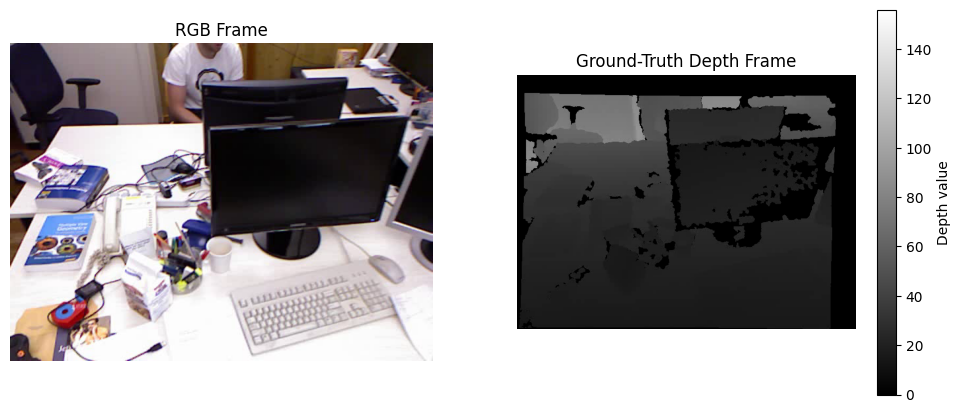

In [ ]:
# Check one RGB/depth frame visually

rgb_cap = cv2.VideoCapture(rgb_video_path)
depth_cap = cv2.VideoCapture(depth_video_path)

# Read the first frame
ret_rgb, rgb_frame = rgb_cap.read()
ret_depth, depth_frame = depth_cap.read()

rgb_cap.release()
depth_cap.release()

print("RGB frame read:", ret_rgb)
print("Depth frame read:", ret_depth)

print("RGB shape:", rgb_frame.shape)
print("Depth shape:", depth_frame.shape)
print("Depth dtype:", depth_frame.dtype)

# Convert RGB frame for matplotlib
rgb_frame = cv2.cvtColor(rgb_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_frame)
plt.title("RGB Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth_frame, cmap="gray")
plt.title("Ground-Truth Depth Frame")
plt.colorbar(label="Depth value")
plt.axis("off")

plt.show()

Depth shape: (480, 640, 3)

Depth dtype: uint8

A true TUM ground-truth depth frame is normally a single-channel 16-bit image, not a 3-channel uint8 image. So the AVI has apparently encoded the depth as a visualized/color-converted video, rather than preserving the original numerical depth values.

The color bar represents the pixel values of the decoded AVI frame, not necessarily physical depth in meters.

The **original depth PNGs inside the `.tgz`** contain actual numerical depth measurements.

For TUM RGB-D:

$$
Depth_{\text{meters}} = \frac{Depth_{\text{pixel}}}{5000}
$$

So, for example:

| Original PNG value | Physical depth |
| -----------------: | -------------: |
|               2500 |          0.5 m |
|               5000 |          1.0 m |
|               7500 |          1.5 m |
|              10000 |          2.0 m |

Therefore, for quantitative ground-truth evaluation, the **original PNG depth files** should be used instead of depth AVI.

The original TUM depth data is 16-bit depth, where the pixel value represents actual measured depth:

depth_in_meters = depth_pixel / 5000

But AVI has been decoded as: uint8 and 3 channels

A uint8 value can only represent: 0–255

So the original 16-bit depth information cannot be preserved directly in that representation.

The three channels also suggest that the AVI has been encoded as a normal video format rather than retaining the original single-channel 16-bit depth images.

In [ ]:
# use the original TUM frame data for the ground truth
dataset_root = "/content/drive/MyDrive/Computer Vision/05/TUM RGB-D dataset/rgbd_dataset_freiburg1_xyz"

print(os.listdir(dataset_root))

['depth.txt', 'accelerometer.txt', 'rgb.txt', 'groundtruth.txt', 'depth', 'rgb']


In [ ]:
# Count the original RGB and depth frames

rgb_dir = os.path.join(dataset_root, "rgb")
depth_dir = os.path.join(dataset_root, "depth")

rgb_files = sorted([
    f for f in os.listdir(rgb_dir)
    if f.endswith(".png")
])

depth_files = sorted([
    f for f in os.listdir(depth_dir)
    if f.endswith(".png")
])

print("RGB frames:", len(rgb_files))
print("Depth frames:", len(depth_files))

print("\nFirst RGB:", rgb_files[0])
print("Last RGB:", rgb_files[-1])

print("\nFirst depth:", depth_files[0])
print("Last depth:", depth_files[-1])

RGB frames: 798
Depth frames: 798

First RGB: 1305031102.175304.png
Last RGB: 1305031128.747363.png

First depth: 1305031102.160407.png
Last depth: 1305031128.754646.png


Depth shape: (480, 640)
Depth dtype: uint16
Min: 0
Max: 18391


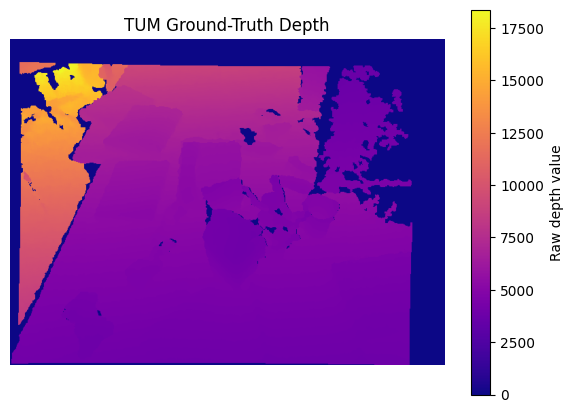

In [ ]:
# Inspect an original ground-truth depth PNG
# In order to confirm that the folder contains the proper 16-bit depth data.

depth_path = os.path.join(depth_dir, depth_files[len(depth_files)//2])

gt_depth = np.array(Image.open(depth_path))

print("Depth shape:", gt_depth.shape)
print("Depth dtype:", gt_depth.dtype)
print("Min:", gt_depth.min())
print("Max:", gt_depth.max())

plt.figure(figsize=(7, 5))
plt.imshow(gt_depth, cmap="plasma")
plt.colorbar(label="Raw depth value")
plt.title("TUM Ground-Truth Depth")
plt.axis("off")
plt.show()

In [ ]:
# Having the actual metric ground truth in meters
gt_depth_m = gt_depth.astype(np.float32) / 5000.0

valid = gt_depth > 0

print("Valid pixels:", valid.sum())
print("Valid percentage:", valid.mean() * 100)
print("Min depth (m):", gt_depth_m[valid].min())
print("Max depth (m):", gt_depth_m[valid].max())
print("Mean depth (m):", gt_depth_m[valid].mean())

Valid pixels: 231941
Valid percentage: 75.50162760416667
Min depth (m): 0.7268
Max depth (m): 3.6782
Mean depth (m): 1.1976355


# Set up Depth Anything V2 Small

Based on the experiment in cv_05_3_DepthAnything_models_Trade-off.ipynb, "Small" uses much less GPU memory while "Base" gives only a modest quality improvement.

Therefore, Small is the sensible model to test.

In [ ]:
model_name = "depth-anything/Depth-Anything-V2-Small-hf"

processor = AutoImageProcessor.from_pretrained(model_name)
model = AutoModelForDepthEstimation.from_pretrained(model_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)
model.eval()

print("Device:", device)
print("Model:", model_name)

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Device: cuda
Model: depth-anything/Depth-Anything-V2-Small-hf


In [ ]:
# Test inference on ONE RGB frame before processing all 798 frames

# Select one RGB frame
test_rgb_path = os.path.join(rgb_dir, rgb_files[len(rgb_files)//2])

image = Image.open(test_rgb_path).convert("RGB")

# Prepare input
inputs = processor(images=image, return_tensors="pt")
inputs = {k: v.to(device) for k, v in inputs.items()}

# Inference
with torch.no_grad():
    outputs = model(**inputs)

predicted_depth = outputs.predicted_depth

# Resize prediction to original image size
depth_pred = predicted_depth.unsqueeze(1)

depth_pred = F.interpolate(
    depth_pred,
    size=image.size[::-1],
    mode="bicubic",
    align_corners=False
)

depth_pred = depth_pred.squeeze().cpu().numpy()

print("Input image size:", image.size)
print("Predicted depth shape:", depth_pred.shape)
print("Predicted depth dtype:", depth_pred.dtype)
print("Predicted min:", depth_pred.min())
print("Predicted max:", depth_pred.max())

Input image size: (640, 480)
Predicted depth shape: (480, 640)
Predicted depth dtype: float32
Predicted min: -0.015734596
Predicted max: 6.828248


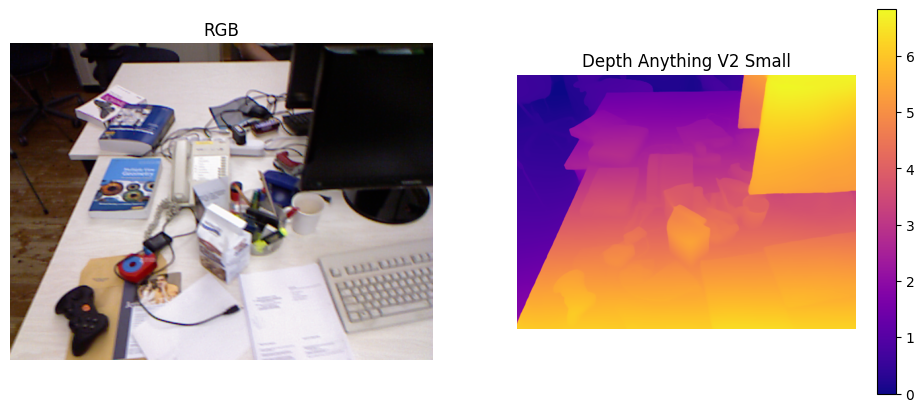

In [ ]:
# Visualizing the test

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("RGB")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth_pred, cmap="plasma")
plt.title("Depth Anything V2 Small")
plt.colorbar()
plt.axis("off")

plt.show()

# Run Depth Anything on all 798 frames

* Read the RGB video frame by frame.
* Run Depth Anything V2 Small.
* Resize the prediction back to 640×480.
* Normalize the prediction for visualization.
* Write the depth maps into an output video.
* Measure actual inference time and FPS.


This part of the code will only have  the time taken by the Depth Anything model for FPS

In [ ]:
# --------------------------------------------------
# Paths
# --------------------------------------------------

output_video_path = "/content/drive/MyDrive/Computer Vision/05/DepthAnything_output_v2_small_video.mp4"

# --------------------------------------------------
# Open input video
# --------------------------------------------------

cap = cv2.VideoCapture(rgb_video_path)

input_fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("Input video:")
print("  FPS:", input_fps)
print("  Frames:", total_frames)
print("  Resolution:", width, "x", height)
print("  Duration:", total_frames / input_fps, "seconds")

# --------------------------------------------------
# Output video
# --------------------------------------------------

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    output_video_path,
    fourcc,
    input_fps,
    (width, height)
)

# --------------------------------------------------
# Timing variables
# --------------------------------------------------

inference_times = []
frame_count = 0

# --------------------------------------------------
# Process frames
# --------------------------------------------------

while True:

    ret, frame = cap.read()

    if not ret:
        break

    # OpenCV BGR -> RGB
    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    image = Image.fromarray(rgb_frame)

    # -----------------------------
    # Preprocessing
    # -----------------------------

    inputs = processor(images=image, return_tensors="pt")
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # -----------------------------
    # Inference timing
    # -----------------------------

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.no_grad():
        outputs = model(**inputs)

    if device.type == "cuda":
        torch.cuda.synchronize()

    inference_time = time.perf_counter() - start_time

    inference_times.append(inference_time)

    # -----------------------------
    # Postprocessing
    # -----------------------------

    predicted_depth = outputs.predicted_depth

    predicted_depth = predicted_depth.unsqueeze(1)

    predicted_depth = F.interpolate(
        predicted_depth,
        size=(height, width),
        mode="bicubic",
        align_corners=False
    )

    predicted_depth = predicted_depth.squeeze().cpu().numpy()

    # Normalize depth for visualization
    depth_min = predicted_depth.min()
    depth_max = predicted_depth.max()

    depth_normalized = (
        (predicted_depth - depth_min)
        / (depth_max - depth_min + 1e-8)
        * 255
    ).astype(np.uint8)

    # Apply colormap
    depth_colored = cv2.applyColorMap(
        depth_normalized,
        cv2.COLORMAP_PLASMA
    )

    # Write output frame
    out.write(depth_colored)

    frame_count += 1

    if frame_count % 50 == 0:
        print(f"Processed {frame_count}/{total_frames} frames")

# --------------------------------------------------
# Release
# --------------------------------------------------

cap.release()
out.release()

# --------------------------------------------------
# Results
# --------------------------------------------------

inference_times = np.array(inference_times)

average_inference_time = inference_times.mean()
inference_fps = 1.0 / average_inference_time
total_inference_time = inference_times.sum()

print("\n===== RESULTS =====")
print("Processed frames:", frame_count)
print("Average inference time:", average_inference_time * 1000, "ms")
print("Inference FPS:", inference_fps)
print("Total inference time:", total_inference_time, "seconds")
print("Output video:", output_video_path)

Input video:
  FPS: 30.0
  Frames: 798
  Resolution: 640 x 480
  Duration: 26.6 seconds
Processed 50/798 frames
Processed 100/798 frames
Processed 150/798 frames
Processed 200/798 frames
Processed 250/798 frames
Processed 300/798 frames
Processed 350/798 frames
Processed 400/798 frames
Processed 450/798 frames
Processed 500/798 frames
Processed 550/798 frames
Processed 600/798 frames
Processed 650/798 frames
Processed 700/798 frames
Processed 750/798 frames

===== RESULTS =====
Processed frames: 798
Average inference time: 60.00976859774416 ms
Inference FPS: 16.663953609006104
Total inference time: 47.887795340999844 seconds
Output video: /content/drive/MyDrive/Computer Vision/05/DepthAnythin_output_v2_small_video.mp4


FPS here is different from the  Task 3.

Here only the neural-network forward pass are measured.

So this is much closer to the actual Depth Anything inference FPS, which is what Task 4 asks for.

In [ ]:
Video(
    "/content/drive/MyDrive/Computer Vision/05/DepthAnythin_output_v2_small_video.mp4",
    embed=True
)

Measure end-to-end FPS (Reading + preprocessing + inference + postprocessing)

In [ ]:
# Rerun the video while measuring the whole process

cap = cv2.VideoCapture(rgb_video_path)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
input_fps = cap.get(cv2.CAP_PROP_FPS)

frame_count = 0

start_total = time.perf_counter()

while True:

    ret, frame = cap.read()

    if not ret:
        break

    # BGR -> RGB
    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    image = Image.fromarray(rgb_frame)

    # Preprocessing
    inputs = processor(images=image, return_tensors="pt")
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Inference
    with torch.no_grad():
        outputs = model(**inputs)

    # Postprocessing
    predicted_depth = outputs.predicted_depth.unsqueeze(1)

    predicted_depth = F.interpolate(
        predicted_depth,
        size=(height, width),
        mode="bicubic",
        align_corners=False
    )

    predicted_depth = predicted_depth.squeeze().cpu().numpy()

    # Depth visualization
    depth_min = predicted_depth.min()
    depth_max = predicted_depth.max()

    depth_normalized = (
        (predicted_depth - depth_min)
        / (depth_max - depth_min + 1e-8)
        * 255
    ).astype(np.uint8)

    depth_colored = cv2.applyColorMap(
        depth_normalized,
        cv2.COLORMAP_PLASMA
    )

    frame_count += 1

cap.release()

end_total = time.perf_counter()

total_time = end_total - start_total
end_to_end_fps = frame_count / total_time
average_total_time = total_time / frame_count

print("===== END-TO-END RESULTS =====")
print("Processed frames:", frame_count)
print("Total processing time:", total_time, "seconds")
print("Average time per frame:", average_total_time * 1000, "ms")
print("End-to-end FPS:", end_to_end_fps)

===== END-TO-END RESULTS =====
Processed frames: 798
Total processing time: 60.32899309300001 seconds
Average time per frame: 75.60024197117795 ms
End-to-end FPS: 13.227470890651947


| FPS                | How calculated                     |        Result |
| ------------------ | ---------------------------------- | ------------: |
| **Input FPS**      | Read from video metadata           |    **30 FPS** |
| **Inference FPS**  | `1 / average model inference time` | **16.66 FPS** |
| **End-to-end FPS** | `798 / total processing time`      | **13.23 FPS** |


The original (input) video produces 30 frames every second, but in here the Depth Anything model can process only about 16.66 frames every second.

To process this video **in real time**, the system would need to process each frame within:

$$
\frac{1}{30} = 0.0333 \text{ seconds} = 33.3 \text{ ms}
$$

But the Depth Anything model takes approximately:

$$
60.01 \text{ ms/frame}
$$

So it can process:

$$
\frac{1}{0.06001} \approx 16.66 \text{ frames/sec}
$$


Since:

$$
30\ \text{FPS} > 16.66\ \text{FPS}
$$

the model is **too slow to keep up with the incoming video** and therefore cannot process the video in real time at the original 30 FPS.


The model falls behind because 30 new frames arrive each second, but it can process only about 16.7.

Therefore, the system cannot process it in real time at the original frame rate on the current hardware.  